In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")


In [2]:
df = pd.read_csv("City_Air_Quality - City_Air_Quality.csv",
                 low_memory=False)
print("Dataset shape:", df.shape)

Dataset shape: (435742, 13)


In [3]:
df.head()

,stn_code,sampling_date,state,location,agency,type,so2,no2,rspm,spm,location_monitoring_station,pm2_5,date
0,150,February - M021990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",4.8,17.4,NaN,NaN,NaN,NaN,1990-02-01
1,151,February - M021990,Andhra Pradesh,Hyderabad,NaN,Industrial Area,3.1,7.0,NaN,NaN,NaN,NaN,1990-02-01
2,152,February - M021990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",6.2,28.5,NaN,NaN,NaN,NaN,1990-02-01
3,150,March - M031990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",6.3,14.7,NaN,NaN,NaN,NaN,1990-03-01
4,151,March - M031990,Andhra Pradesh,Hyderabad,NaN,Industrial Area,4.7,7.5,NaN,NaN,NaN,NaN,1990-03-01


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 435742 entries, 0 to 435741
Data columns (total 13 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   stn_code                     291665 non-null  object 
 1   sampling_date                435739 non-null  object 
 2   state                        435742 non-null  object 
 3   location                     435739 non-null  object 
 4   agency                       286261 non-null  object 
 5   type                         430349 non-null  object 
 6   so2                          401096 non-null  float64
 7   no2                          419509 non-null  float64
 8   rspm                         395520 non-null  float64
 9   spm                          198355 non-null  float64
 10  location_monitoring_station  408251 non-null  object 
 11  pm2_5                        9314 non-null    float64
 12  date                         435735 non-null  object 
dtyp

In [5]:
df.describe()

,so2,no2,rspm,spm,pm2_5
count,401096.000000,419509.000000,395520.000000,198355.000000,9314.000000
mean,10.829414,25.809623,108.832784,220.783480,40.791467
std,11.177187,18.503086,74.872430,151.395457,30.832525
min,0.000000,0.000000,0.000000,0.000000,3.000000
25%,5.000000,14.000000,56.000000,111.000000,24.000000
50%,8.000000,22.000000,90.000000,187.000000,32.000000
75%,13.700000,32.200000,142.000000,296.000000,46.000000
max,909.000000,876.000000,6307.033333,3380.000000,504.000000


In [6]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
stn_code                       144077
sampling_date                       3
state                               0
location                            3
agency                         149481
type                             5393
so2                             34646
no2                             16233
rspm                            40222
spm                            237387
location_monitoring_station     27491
pm2_5                          426428
date                                7
dtype: int64

Total missing values: 1081371


In [7]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("Available columns:")
print(df.columns.tolist())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nAvailable locations:")
print(df["location"].nunique())

Available columns:
['stn_code', 'sampling_date', 'state', 'location', 'agency', 'type', 'so2', 'no2', 'rspm', 'spm', 'location_monitoring_station', 'pm2_5', 'date']

Date range:
1987-01-01 00:00:00 to 2015-12-31 00:00:00

Available locations:
304


Select a city for analysis

In [8]:
print("Top 10 locations:")
print(df["location"].value_counts().head(10))

city_name = df["location"].mode()[0]

city_df = df[df["location"] == city_name].copy()
city_df = city_df.sort_values("date")

print("\nSelected location:", city_name)
print("Number of records:", len(city_df))

Top 10 locations:
location
Guwahati      9984
Hyderabad     9667
Delhi         8551
Chandigarh    8520
Jaipur        7850
Nagpur        7829
Kolkata       7733
Kanpur        7545
Agra          7306
Kochi         7263
Name: count, dtype: int64

Selected location: Guwahati
Number of records: 9984


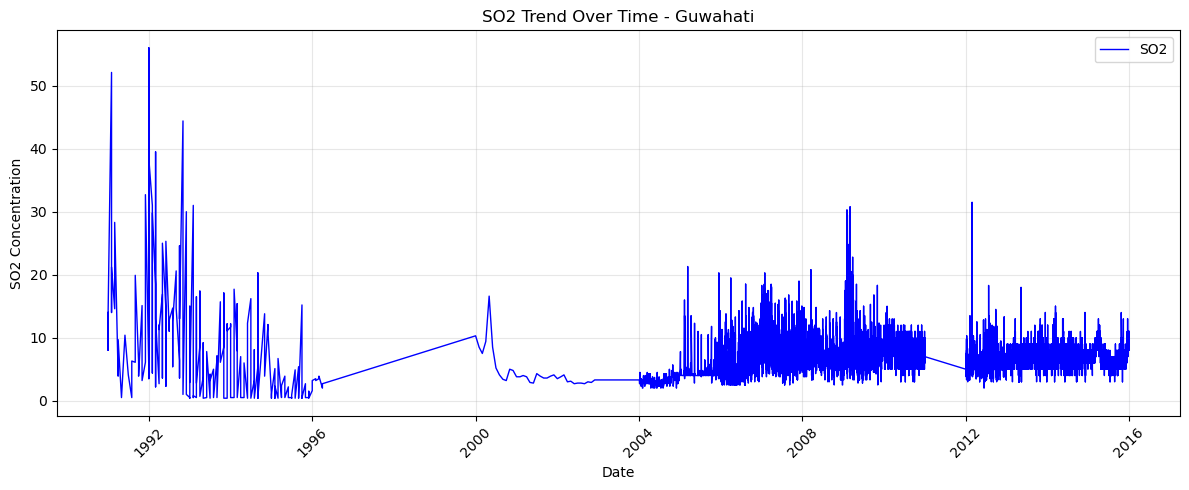

In [10]:
#Plot pollution trends over time
data = city_df.dropna(subset=["date", "so2"])

plt.figure(figsize=(12, 5))
plt.plot(data["date"], data["so2"],
         color="blue", linewidth=1,
         label="SO2")

plt.title(f"SO2 Trend Over Time - {city_name}")
plt.xlabel("Date")
plt.ylabel("SO2 Concentration")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

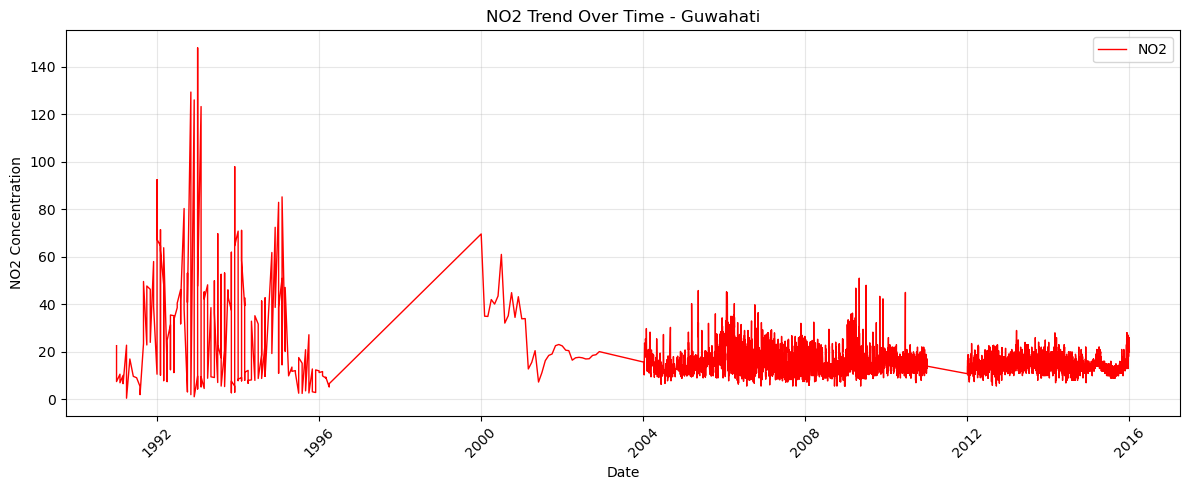

In [11]:
#Plot NO₂ trend
data = city_df.dropna(subset=["date", "no2"])

plt.figure(figsize=(12, 5))
plt.plot(data["date"], data["no2"],
         color="red", linewidth=1,
         label="NO2")

plt.title(f"NO2 Trend Over Time - {city_name}")
plt.xlabel("Date")
plt.ylabel("NO2 Concentration")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

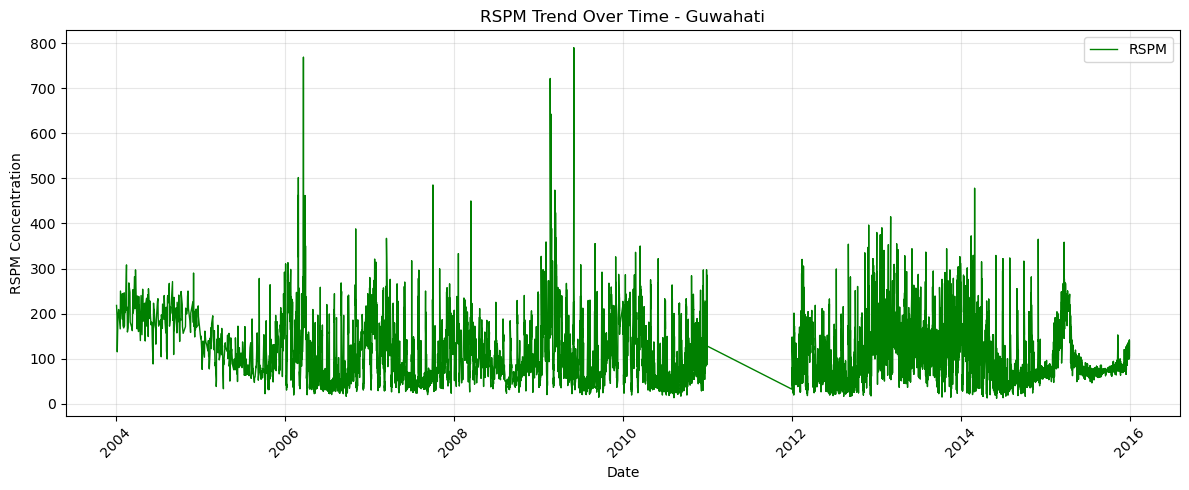

In [13]:
#Plot RSPM trend
data = city_df.dropna(subset=["date", "rspm"])

plt.figure(figsize=(12, 5))
plt.plot(data["date"], data["rspm"],
         color="green", linewidth=1,
         label="RSPM")

plt.title(f"RSPM Trend Over Time - {city_name}")
plt.xlabel("Date")
plt.ylabel("RSPM Concentration")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

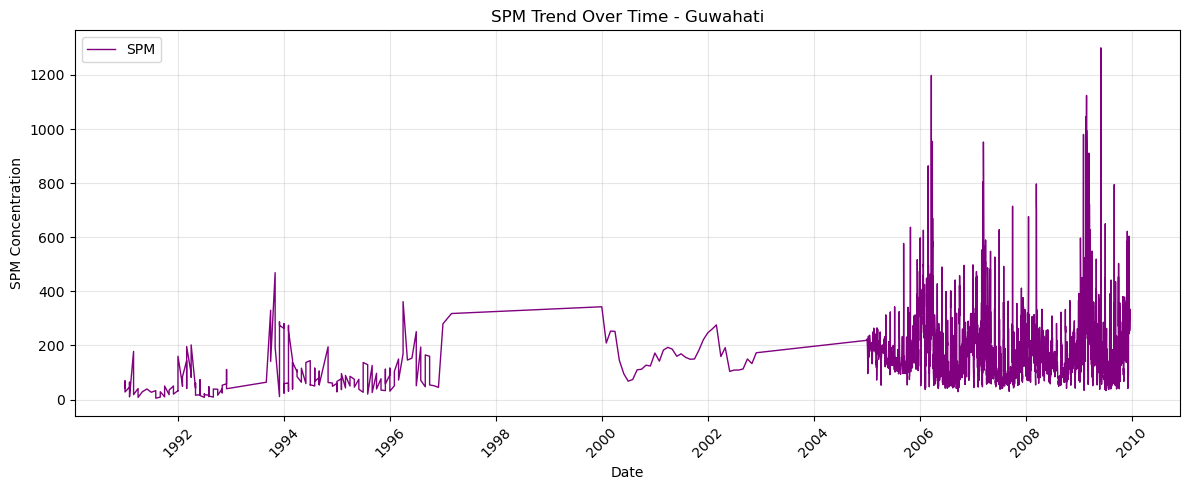

In [14]:
#Plot SPM trend
data = city_df.dropna(subset=["date", "spm"])

plt.figure(figsize=(12, 5))
plt.plot(data["date"], data["spm"],
         color="purple", linewidth=1,
         label="SPM")

plt.title(f"SPM Trend Over Time - {city_name}")
plt.xlabel("Date")
plt.ylabel("SPM Concentration")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

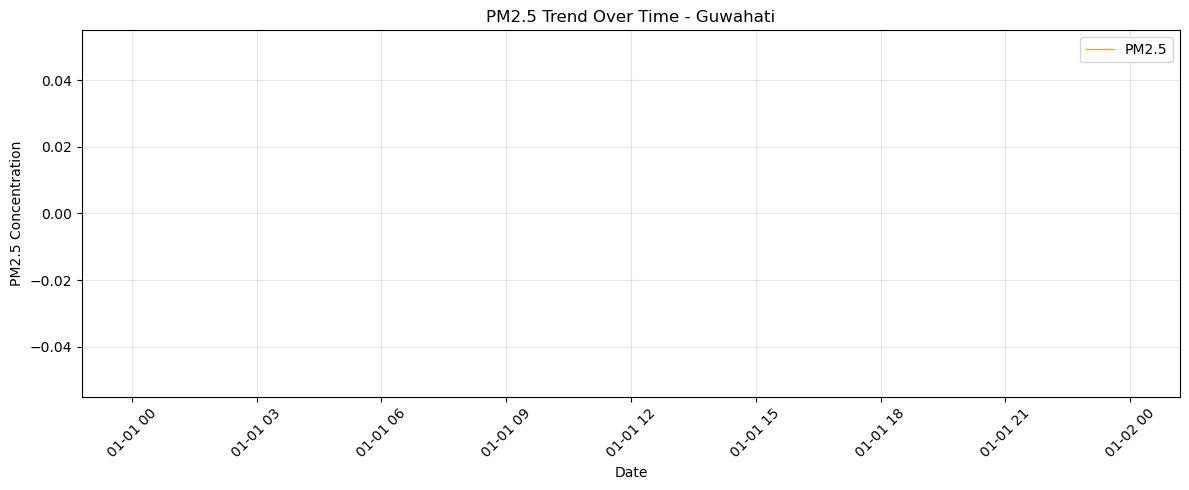

In [15]:
#Plot PM2.5 trend
data = city_df.dropna(subset=["date", "pm2_5"])

plt.figure(figsize=(12, 5))
plt.plot(data["date"], data["pm2_5"],
         color="orange", linewidth=1,
         label="PM2.5")

plt.title(f"PM2.5 Trend Over Time - {city_name}")
plt.xlabel("Date")
plt.ylabel("PM2.5 Concentration")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

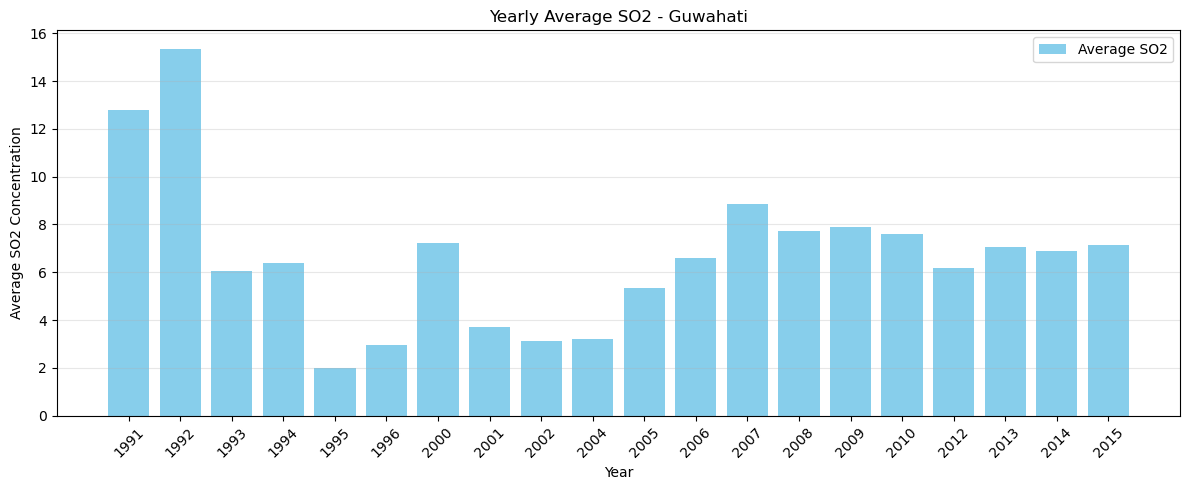

In [16]:
yearly_so2 = (
    city_df.dropna(subset=["date", "so2"])
    .assign(year=lambda x: x["date"].dt.year)
    .groupby("year")["so2"]
    .mean()
)

plt.figure(figsize=(12, 5))
plt.bar(yearly_so2.index.astype(str), yearly_so2.values,
        color="skyblue", label="Average SO2")

plt.title(f"Yearly Average SO2 - {city_name}")
plt.xlabel("Year")
plt.ylabel("Average SO2 Concentration")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

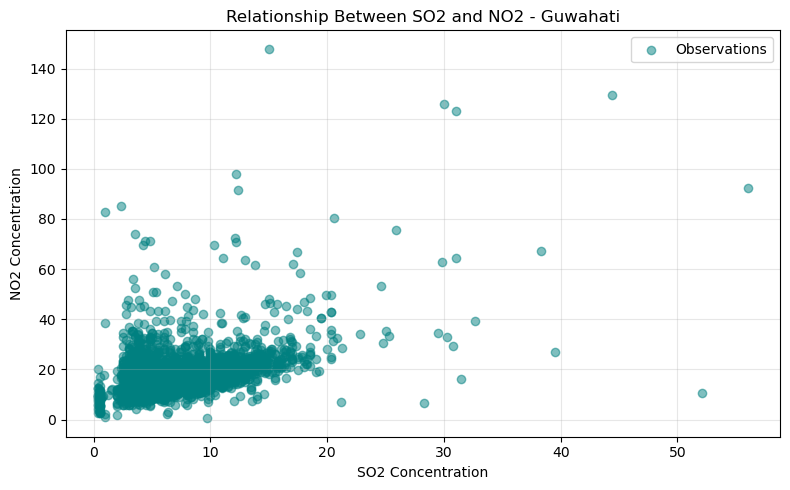

In [17]:
#Scatter plot: SO₂ vs NO₂
data = city_df.dropna(subset=["so2", "no2"])

plt.figure(figsize=(8, 5))
plt.scatter(data["so2"], data["no2"],
            color="teal", alpha=0.5, label="Observations")

plt.title(f"Relationship Between SO2 and NO2 - {city_name}")
plt.xlabel("SO2 Concentration")
plt.ylabel("NO2 Concentration")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

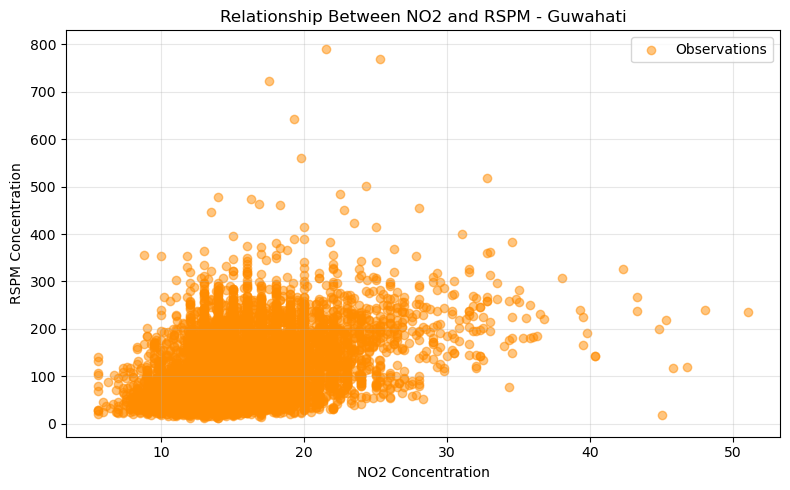

In [19]:
#Scatter plot: NO₂ vs RSP
data = city_df.dropna(subset=["no2", "rspm"])

plt.figure(figsize=(8, 5))
plt.scatter(data["no2"], data["rspm"],
            color="darkorange", alpha=0.5,
            label="Observations")

plt.title(f"Relationship Between NO2 and RSPM - {city_name}")
plt.xlabel("NO2 Concentration")
plt.ylabel("RSPM Concentration")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



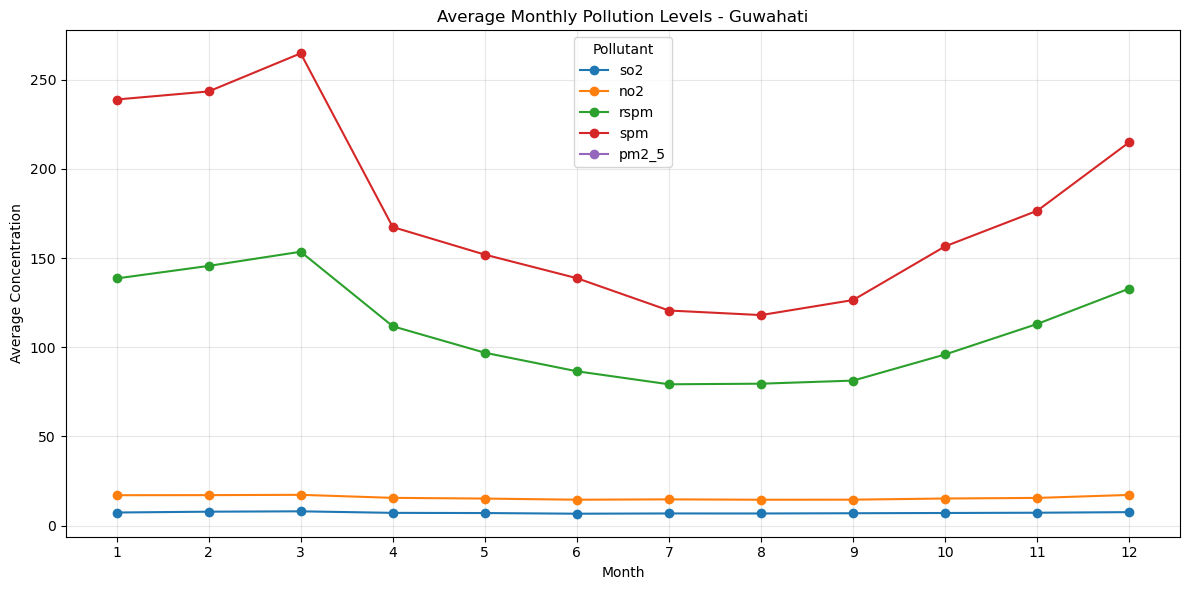

In [20]:
#Compare monthly pollution levels
monthly_data = city_df.dropna(subset=["date"]).copy()
monthly_data["month"] = monthly_data["date"].dt.month

monthly_avg = monthly_data.groupby("month")[
    ["so2", "no2", "rspm", "spm", "pm2_5"]
].mean()

monthly_avg.plot(kind="line", figsize=(12, 6), marker="o")

plt.title(f"Average Monthly Pollution Levels - {city_name}")
plt.xlabel("Month")
plt.ylabel("Average Concentration")
plt.xticks(range(1, 13))
plt.legend(title="Pollutant")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
print("AIR QUALITY VISUALIZATION SUMMARY")
print("---------------------------------")

print("Total records:", len(df))
print("Number of states:", df["state"].nunique())
print("Number of locations:", df["location"].nunique())

print("Date range:",
      df["date"].min(), "to", df["date"].max())

print("\nAverage pollutant levels for selected location:")
print(city_df[["so2", "no2", "rspm", "spm", "pm2_5"]].mean().round(2))

AIR QUALITY VISUALIZATION SUMMARY
---------------------------------
Total records: 435742
Number of states: 37
Number of locations: 304
Date range: 1987-01-01 00:00:00 to 2015-12-31 00:00:00

Average pollutant levels for selected location:
so2        7.16
no2       15.66
rspm     109.66
spm      177.26
pm2_5       NaN
dtype: float64
